# Decoding Strategies

A language model does not output text. At each step it outputs a **probability distribution** over its vocabulary. A **decoding strategy** is the rule that selects one token from that distribution. The same model can produce dull, repetitive text or varied, natural text. The difference comes only from the decoding strategy.

**After this lesson you can:**

1. Explain greedy decoding, beam search, temperature, top-k, top-p (nucleus) and min-p sampling.
2. Implement each strategy from the raw logits of a real model (GPT-2).
3. Measure the trade-off between diversity and likelihood.
4. Select decoding settings for a task.

Lesson 09 showed how a decoder model produces the next-token distribution. This lesson shows what to do with that distribution.

In [1]:
import math
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from transformers import AutoModelForCausalLM, AutoTokenizer
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()          # hide download progress messages
plt.rcParams.update({"figure.facecolor": "white", "axes.grid": True, "grid.alpha": 0.3})

device = "cuda" if torch.cuda.is_available() else "cpu"
tokenizer = AutoTokenizer.from_pretrained("gpt2")
model = AutoModelForCausalLM.from_pretrained("gpt2").to(device).eval()
print(f"Model: GPT-2 small ({sum(p.numel() for p in model.parameters()) / 1e6:.0f}M parameters) on {device}")
print(f"Vocabulary size: {model.config.vocab_size:,} tokens")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Model: GPT-2 small (124M parameters) on cuda
Vocabulary size: 50,257 tokens


## 1. From Logits to a Choice

For a prompt $x_{<t}$, the model produces one score (a **logit**) $z_i$ for every token $i$ in the vocabulary. The softmax function converts the logits to probabilities:

$$
p(i \mid x_{<t}) = \frac{e^{z_i}}{\sum_{j} e^{z_j}}
$$

Generation repeats three steps: compute the distribution, select one token, append the token to the input. The decoding strategy is step 2. The table gives an overview.

| Strategy | Rule | Deterministic | Typical use |
| :--- | :--- | :-: | :--- |
| Greedy | select the most probable token | yes | short factual answers, classification-like outputs |
| Beam search | keep the $B$ best partial sequences | yes | translation, summarisation, speech recognition |
| Temperature sampling | sample from $\text{softmax}(z / T)$ | no | controls creativity |
| Top-k | sample from the $k$ most probable tokens | no | removes the long tail |
| Top-p (nucleus) | sample from the smallest set with probability mass $\ge p$ | no | default in most chat APIs |
| Min-p | keep tokens with $p_i \ge p_{\min} \cdot p_{\max}$ | no | newer default in open-source tools (2024) |

The cell below shows the real next-token distribution of GPT-2 for one prompt.

In [2]:
prompt = "The best way to learn a new programming language is"
input_ids = tokenizer(prompt, return_tensors="pt").input_ids.to(device)

with torch.no_grad():
    logits = model(input_ids).logits[0, -1]          # logits for the next token
probs = F.softmax(logits, dim=-1)

top = torch.topk(probs, 10)
table = pd.DataFrame({
    "token": [repr(tokenizer.decode([i])) for i in top.indices.tolist()],
    "logit": logits[top.indices].cpu().numpy().round(2),
    "probability": top.values.cpu().numpy().round(4),
})
print(f"Prompt: {prompt!r}\n")
print(table.to_string(index=False))
sorted_probs = torch.sort(probs, descending=True).values.cpu().numpy()
print(f"\nTop-10 tokens hold {sorted_probs[:10].sum():.1%} of the probability mass.")
print(f"Tokens needed to cover 90% of the mass: {int(np.searchsorted(np.cumsum(sorted_probs), 0.9)) + 1:,}")

Prompt: 'The best way to learn a new programming language is'

      token      logit  probability
      ' to' -69.349998       0.7218
      ' by' -71.330002       0.0999
 ' through' -72.040001       0.0487
    ' with' -72.809998       0.0227
     ' not' -73.839996       0.0081
     ' for' -74.120003       0.0061
' learning' -74.480003       0.0043
      ' if' -74.500000       0.0042
   ' learn' -74.519997       0.0041
    ' from' -74.580002       0.0039



Top-10 tokens hold 92.4% of the probability mass.
Tokens needed to cover 90% of the mass: 5


For this prompt, a few tokens hold most of the probability mass (see the last two lines). But the vocabulary has 50,257 tokens, and the **long tail** of unlikely tokens still holds the rest. For more open prompts the distribution is much flatter. Every strategy below is a different answer to one question: *which part of this distribution do we trust?*

## 2. Greedy Decoding

Greedy decoding selects $\arg\max_i \, p(i \mid x_{<t})$ at every step. It is fast and deterministic. But a sequence of locally best choices is not the most probable sequence, and greedy text often falls into **repetition loops**.

The function below implements the generation loop by hand. All later strategies use the same loop and only change how the next token is selected.

In [3]:
@torch.no_grad()
def generate(prompt, select_fn, max_new_tokens=40, seed=0):
    """Autoregressive generation with a KV cache. `select_fn(logits) -> token id` is the decoding strategy."""
    torch.manual_seed(seed)
    ids = tokenizer(prompt, return_tensors="pt").input_ids.to(device)
    out = model(ids, use_cache=True)
    generated = []
    for _ in range(max_new_tokens):
        next_id = select_fn(out.logits[0, -1])
        generated.append(next_id)
        out = model(torch.tensor([[next_id]], device=device), past_key_values=out.past_key_values, use_cache=True)
    return generated

def greedy(logits):
    return int(torch.argmax(logits))

def repetition_rate(token_ids, n=3):
    """Share of n-grams that already appeared earlier in the same text (0 = no repetition)."""
    grams = [tuple(token_ids[i:i + n]) for i in range(len(token_ids) - n + 1)]
    return 1 - len(set(grams)) / max(1, len(grams))

ids_greedy = generate(prompt, greedy, max_new_tokens=60)
print(prompt + tokenizer.decode(ids_greedy))
print(f"\n3-gram repetition rate: {repetition_rate(ids_greedy):.0%}")

The best way to learn a new programming language is to learn it from a beginner.

The best way to learn a new programming language is to learn it from a beginner. Learn the language from a beginner.

Learn the language from a beginner.

Learn the language from a beginner.

Learn the language from a beginner.

3-gram repetition rate: 53%


## 3. Beam Search

Beam search keeps the $B$ most probable **partial sequences** (beams). At each step it expands every beam with every token and keeps the $B$ best by total log-probability:

$$
\text{score}(y_{1:t}) = \sum_{s=1}^{t} \log p(y_s \mid y_{<s}, x)
$$

Longer sequences collect more negative log terms, so beam search prefers short outputs. A **length penalty** divides the score by $t^{\alpha}$ to correct this. Hugging Face `generate()` implements beam search; `no_repeat_ngram_size` blocks repeated n-grams.

In [4]:
def sequence_logprob(prompt, gen_ids):
    """Average log-probability per token that GPT-2 assigns to the generated continuation."""
    ids = tokenizer(prompt, return_tensors="pt").input_ids.to(device)
    full = torch.cat([ids, torch.tensor([gen_ids], device=device)], dim=1)
    with torch.no_grad():
        logp = F.log_softmax(model(full).logits[0, :-1], dim=-1)
    targets = full[0, 1:]
    token_logp = logp[torch.arange(len(targets)), targets][ids.shape[1] - 1:]
    return float(token_logp.mean())

enc = tokenizer(prompt, return_tensors="pt").to(device)
results = {}
for name, kwargs in [("beam=1 (greedy)", dict(num_beams=1)),
                     ("beam=5", dict(num_beams=5)),
                     ("beam=5 + no_repeat_ngram=3", dict(num_beams=5, no_repeat_ngram_size=3))]:
    out = model.generate(**enc, max_new_tokens=40, do_sample=False, pad_token_id=tokenizer.eos_token_id, **kwargs)
    gen = out[0, enc.input_ids.shape[1]:].tolist()
    results[name] = gen
    print(f"[{name}]  avg log-prob {sequence_logprob(prompt, gen):.3f}, repetition {repetition_rate(gen):.0%}")
    print("  " + tokenizer.decode(gen).replace("\n", " ") + "\n")

[beam=1 (greedy)]  avg log-prob -0.838, repetition 29%
   to learn it from a beginner.  The best way to learn a new programming language is to learn it from a beginner. Learn the language from a beginner.  Learn the language from a



[beam=5]  avg log-prob -0.584, repetition 50%
   to learn how to use it.  The best way to learn a new programming language is to learn how to use it.  The best way to learn a new programming language is to learn



[beam=5 + no_repeat_ngram=3]  avg log-prob -1.176, repetition 0%
   to learn it in a language that is easy to learn and easy to understand.  Learning a new language is like learning a language from scratch. It takes a lot of time, effort, and



Beam search finds continuations with a higher average log-probability than greedy decoding. That is its purpose. But high probability is not the same as good text: for open-ended writing, the most probable sequences are often generic and repetitive. This is why chat models use **sampling**, and beam search stays popular for tasks with one correct output, such as translation.

## 4. Temperature

Sampling selects the next token at random, in proportion to its probability. **Temperature** $T$ rescales the logits before the softmax:

$$
p_T(i) = \frac{e^{z_i / T}}{\sum_j e^{z_j / T}}
$$

- $T < 1$ makes the distribution sharper (more conservative). $T \to 0$ becomes greedy decoding.
- $T = 1$ keeps the model distribution.
- $T > 1$ makes the distribution flatter (more random).

The plot shows the real GPT-2 distribution from Section 1 at three temperatures.

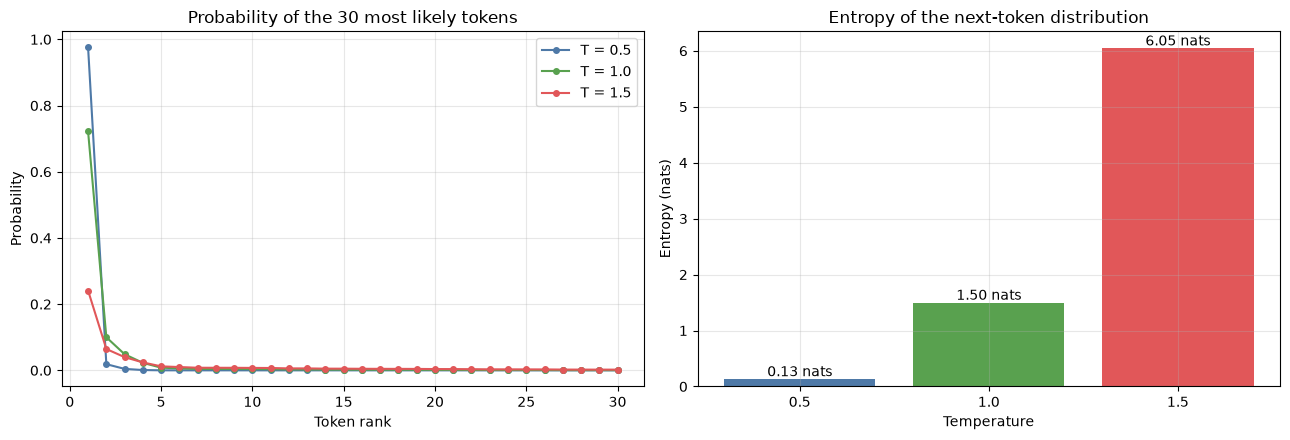

T = 0.5: top-1 probability 97.5%, entropy 0.13 nats
T = 1.0: top-1 probability 72.2%, entropy 1.50 nats
T = 1.5: top-1 probability 24.1%, entropy 6.05 nats


In [5]:
temps = [0.5, 1.0, 1.5]
k_show = 30
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
order = torch.argsort(logits, descending=True)[:k_show]
for T, color in zip(temps, ["#4E79A7", "#59A14F", "#E15759"]):
    pT = F.softmax(logits / T, dim=-1)
    axes[0].plot(range(1, k_show + 1), pT[order].cpu().numpy(), marker="o", ms=4, color=color, label=f"T = {T}")
    ent = float(-(pT * torch.log(pT + 1e-12)).sum())
    axes[1].bar(str(T), ent, color=color)
    axes[1].text(str(T), ent + 0.05, f"{ent:.2f} nats", ha="center")
axes[0].set(title="Probability of the 30 most likely tokens", xlabel="Token rank", ylabel="Probability")
axes[0].legend()
axes[1].set(title="Entropy of the next-token distribution", xlabel="Temperature", ylabel="Entropy (nats)")
plt.tight_layout()
plt.show()

for T in temps:
    pT = F.softmax(logits / T, dim=-1)
    print(f"T = {T}: top-1 probability {float(pT.max()):.1%}, entropy {float(-(pT * torch.log(pT + 1e-12)).sum()):.2f} nats")

## 5. Truncation: Top-k, Top-p and Min-p

Pure sampling can select a token from the **long tail**: thousands of tokens that are individually unlikely but together hold a large share of the mass. One bad token can derail the rest of the text. **Truncation** methods remove the tail before sampling, then renormalise the remaining probabilities.

- **Top-k**: keep the $k$ most probable tokens. The problem: a fixed $k$ is too large when the model is confident and too small when it is uncertain.
- **Top-p (nucleus sampling)**: sort the tokens and keep the smallest set $V_p$ whose total probability is at least $p$:
$$
V_p = \text{smallest set such that } \sum_{i \in V_p} p(i) \ge p
$$
  The set adapts: it is small when the model is confident and large when it is uncertain.
- **Min-p**: keep every token with $p(i) \ge p_{\min} \cdot \max_j p(j)$. The threshold scales with the confidence of the top token. Min-p was proposed in 2024 and is now available in Hugging Face, vLLM and llama.cpp.

The function below implements all three on top of temperature.

In [6]:
def make_sampler(temperature=1.0, top_k=0, top_p=1.0, min_p=0.0):
    def select(logits):
        z = logits / max(temperature, 1e-6)
        p = F.softmax(z, dim=-1)
        keep = torch.ones_like(p, dtype=torch.bool)
        if top_k > 0:
            keep &= p >= torch.topk(p, top_k).values[-1]
        if top_p < 1.0:
            sp, si = torch.sort(p, descending=True)
            cum = torch.cumsum(sp, dim=0)
            in_nucleus = (cum - sp) < top_p              # keep tokens until the mass reaches top_p
            mask = torch.zeros_like(keep)
            mask[si[in_nucleus]] = True
            keep &= mask
        if min_p > 0.0:
            keep &= p >= min_p * p.max()
        p = torch.where(keep, p, torch.zeros_like(p))
        return int(torch.multinomial(p / p.sum(), 1))
    return select

def candidate_count(logits, **kw):
    """How many tokens a sampler keeps for this distribution."""
    p = F.softmax(logits / kw.get("temperature", 1.0), dim=-1)
    keep = torch.ones_like(p, dtype=torch.bool)
    if kw.get("top_k"):
        keep &= p >= torch.topk(p, kw["top_k"]).values[-1]
    if kw.get("top_p", 1.0) < 1.0:
        sp, si = torch.sort(p, descending=True)
        m = torch.zeros_like(keep); m[si[(torch.cumsum(sp, 0) - sp) < kw["top_p"]]] = True
        keep &= m
    if kw.get("min_p"):
        keep &= p >= kw["min_p"] * p.max()
    return int(keep.sum())

# Compare a confident prompt with an open prompt
prompts = {"confident": "Thank you very", "open": "She opened the door and saw a"}
rows = []
for label, pr in prompts.items():
    with torch.no_grad():
        lg = model(tokenizer(pr, return_tensors="pt").input_ids.to(device)).logits[0, -1]
    rows.append({"prompt": label, "top-1 prob": f"{float(F.softmax(lg, -1).max()):.1%}",
                 "top_k=50": candidate_count(lg, top_k=50),
                 "top_p=0.9": candidate_count(lg, top_p=0.9),
                 "min_p=0.05": candidate_count(lg, min_p=0.05)})
print("Number of candidate tokens each method keeps:\n")
print(pd.DataFrame(rows).to_string(index=False))

Number of candidate tokens each method keeps:

   prompt top-1 prob  top_k=50  top_p=0.9  min_p=0.05
confident      99.2%        50          1           1
     open      17.2%        50       1307          12


Top-k keeps 50 tokens in both cases: too many for the confident prompt, where only one continuation makes sense. Top-p and min-p **adapt**: both keep almost nothing for the confident prompt. For the open prompt, the difference between them appears. Top-p must collect 90% of a flat distribution, so it keeps a very long tail of rare tokens. Min-p keeps only tokens that are reasonably close to the best one. This is why min-p works well together with a higher temperature.

## 6. Experiment: Diversity vs Likelihood

Now generate 8 continuations per strategy and measure two properties:

- **Distinct-2**: the share of unique bigrams across all samples (higher = more diverse).
- **Average log-probability** per token under GPT-2 (higher = more predictable for the model). Very low values often mean incoherent text.

A good strategy is diverse without collapsing into low-probability noise.

In [7]:
strategies = {
    "greedy": greedy,
    "pure sampling (T=1)": make_sampler(temperature=1.0),
    "T=0.7": make_sampler(temperature=0.7),
    "T=1.5": make_sampler(temperature=1.5),
    "top-k=40": make_sampler(top_k=40),
    "top-p=0.9": make_sampler(top_p=0.9),
    "min-p=0.05": make_sampler(min_p=0.05),
    "T=1.2 + min-p=0.1": make_sampler(temperature=1.2, min_p=0.1),
}
exp_prompt = "In the future, artificial intelligence will"
n_samples, n_tokens = 8, 40

def distinct_n(samples, n=2):
    grams = [tuple(s[i:i + n]) for s in samples for i in range(len(s) - n + 1)]
    return len(set(grams)) / max(1, len(grams))

records, examples = [], {}
t0 = time.time()
for name, fn in strategies.items():
    samples = [generate(exp_prompt, fn, max_new_tokens=n_tokens, seed=s) for s in range(n_samples)]
    records.append({"strategy": name,
                    "distinct-2": distinct_n(samples),
                    "avg log-prob": np.mean([sequence_logprob(exp_prompt, s) for s in samples]),
                    "repetition": np.mean([repetition_rate(s) for s in samples])})
    examples[name] = tokenizer.decode(samples[0]).replace("\n", " ")
res = pd.DataFrame(records).set_index("strategy")
print(f"{len(strategies) * n_samples} generations in {time.time() - t0:.0f} s\n")
print(res.round(3).to_string())

64 generations in 48 s

                     distinct-2  avg log-prob  repetition
strategy                                                 
greedy                    0.096        -1.476       0.184
pure sampling (T=1)       0.984        -3.733       0.000
T=0.7                     0.856        -2.356       0.023
T=1.5                     1.000        -8.850       0.000
top-k=40                  0.865        -2.454       0.030
top-p=0.9                 0.965        -3.212       0.000
min-p=0.05                0.872        -2.184       0.023
T=1.2 + min-p=0.1         0.859        -2.246       0.026


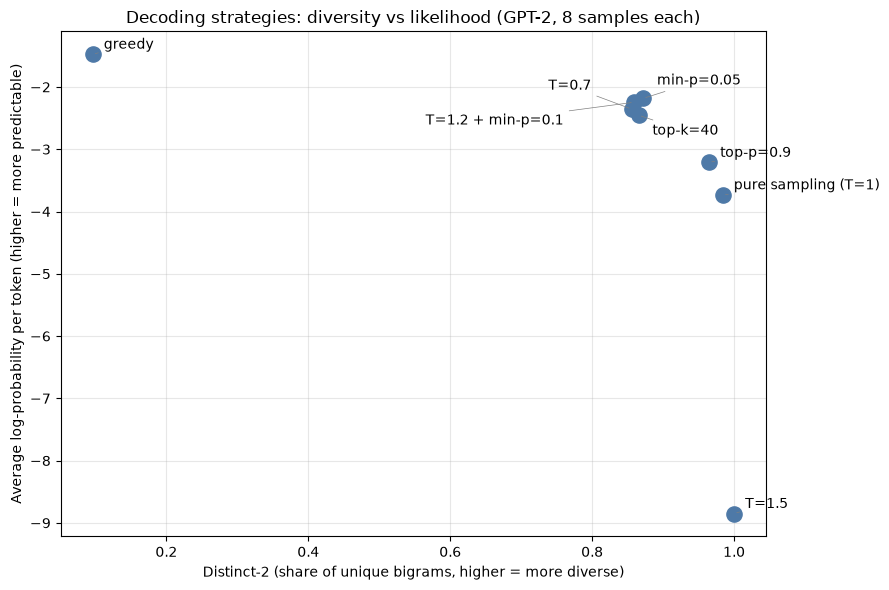

[greedy]  be able to do things like search for information about people, and to do things like search for information about people.  "We're going to see a lot of things that are going to be

[T=1.5]  develop extraction skills ... conventional actors will become even tens building reinforcement networks," Zakcan Hammeran together longevity coach Philip Wittrock LLP will christe x.- Onesphonyms Bil

[top-p=0.9]  develop sophisticated algorithms that can quickly deduce patterns of building blocks and create reliable tools for building artificial machines," said Richard Waldorf, a professor of computer science

[min-p=0.05]  help you keep your tasks at your fingertips, rather than be overwhelmed by distractions. And while artificial intelligence might be an exciting technology, there are already plenty of benefits for wo



In [8]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(res["distinct-2"], res["avg log-prob"], s=120, color="#4E79A7", zorder=3)
offsets = {"T=0.7": (-60, 14), "min-p=0.05": (10, 10), "top-k=40": (10, -14), "T=1.2 + min-p=0.1": (-150, -16)}
for name, r in res.iterrows():
    ax.annotate(name, (r["distinct-2"], r["avg log-prob"]), textcoords="offset points",
                xytext=offsets.get(name, (8, 4)), fontsize=10, arrowprops=dict(arrowstyle="-", color="grey", lw=0.5))
ax.set(title="Decoding strategies: diversity vs likelihood (GPT-2, 8 samples each)",
       xlabel="Distinct-2 (share of unique bigrams, higher = more diverse)",
       ylabel="Average log-probability per token (higher = more predictable)")
plt.tight_layout()
plt.show()

for name in ["greedy", "T=1.5", "top-p=0.9", "min-p=0.05"]:
    print(f"[{name}] {examples[name][:200]}\n")

## 7. Analysis

Read the table and the plot together:

- **Greedy** has the highest log-probability and the lowest diversity. All 8 samples are identical, because greedy decoding ignores the seed.
- **Temperature** moves along one line: lower $T$ is more predictable and less diverse; $T = 1.5$ is the most diverse and the least probable. Its samples often contain broken phrases.
- **Top-p, top-k and min-p** keep most of the diversity of pure sampling but stay closer to the model's likely region. They remove the tail tokens that cause incoherent jumps.
- **Min-p with a higher temperature** shows why min-p is useful: it allows more creative sampling ($T > 1$) and still cuts the tail.

The exact numbers change with the prompt and the model. The pattern does not.

## 8. Practical Settings

| Task | Recommended setting |
| :--- | :--- |
| Extraction, classification, code completion with one answer | greedy or $T \le 0.2$ |
| Translation, summarisation | beam search ($B = 4\text{–}5$) or $T \approx 0.3$ |
| Chat assistant | $T \approx 0.7$, top-p $= 0.9$ (or min-p $= 0.05$) |
| Creative writing, brainstorming | $T = 1.0\text{–}1.3$ with min-p $= 0.05\text{–}0.1$ |
| Reasoning models | follow the model card; many recommend $T \approx 0.6$, top-p $= 0.95$ |

Two related techniques appear later in the course:

- **Constrained (structured) decoding** masks tokens that would break a JSON schema or a grammar, so the output is always valid (M36, SGLang & Structured Generation).
- **Speculative decoding** uses a small draft model to propose tokens that the large model verifies. It makes generation faster without changing the output distribution (M36).

*Insight: The decoding strategy is part of the model's behaviour. The same weights give repetitive text with greedy decoding and natural text with top-p or min-p sampling. Report decoding settings with every generated example or benchmark result.*

## Real-World Use Case or Analogy

Think of a **jazz musician** who chooses the next note:

- **Greedy decoding** plays the safest note every time. The melody is correct but boring, and it soon repeats the same phrase.
- **Beam search** plans several bars ahead and plays the most "correct" melody. This is right for playing a known song (translation), but not for improvising.
- **Temperature** sets how adventurous the musician is. Too low gives a scale exercise. Too high gives random notes.
- **Top-p and min-p** are the musician's sense of harmony: the musician improvises freely, but only with notes that fit the chord.

Product teams make the same choice. A customer-support bot uses a low temperature so that answers stay consistent. A marketing-copy generator uses higher temperature with min-p or top-p, so that each call gives a fresh but sensible variant.